# 🔬 Pengaruh Perplexity pada t-SNE

**Tugas Data Mining — t-SNE**

Mengamati bagaimana parameter **perplexity** (5, 30, 50, 100) memengaruhi hasil embedding t-SNE pada tiga dataset sintetis: **circles**, **S-curve**, dan **uniform grid** (diadaptasi dari contoh scikit-learn, dengan fungsi `run_tsne` yang dapat dipakai ulang dan eksperimen tambahan).

- Perplexity kecil → fokus pada struktur lokal, cluster cenderung terpecah
- Perplexity besar → mempertahankan struktur global, bentuk asli lebih terlihat

In [ ]:
from time import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import NullFormatter
from sklearn import datasets, manifold

In [ ]:
n_samples = 150
n_components = 2
perplexities = [5, 30, 50, 100]

In [ ]:
def run_tsne(X, perplexity, n_components=2, max_iter=500):
    tsne = manifold.TSNE(
        n_components=n_components,
        init="random",
        random_state=0,
        perplexity=perplexity,
        learning_rate="auto",
        max_iter=max_iter,
    )
    return tsne.fit_transform(X)

circles, perplexity=5 in 4.68 sec
circles, perplexity=30 in 0.58 sec
circles, perplexity=50 in 0.53 sec
circles, perplexity=100 in 0.54 sec
S-curve, perplexity=5 in 0.35 sec
S-curve, perplexity=30 in 0.50 sec
S-curve, perplexity=50 in 0.41 sec
S-curve, perplexity=100 in 0.46 sec
uniform grid, perplexity=5 in 0.34 sec
uniform grid, perplexity=30 in 0.48 sec
uniform grid, perplexity=50 in 0.45 sec
uniform grid, perplexity=100 in 0.45 sec


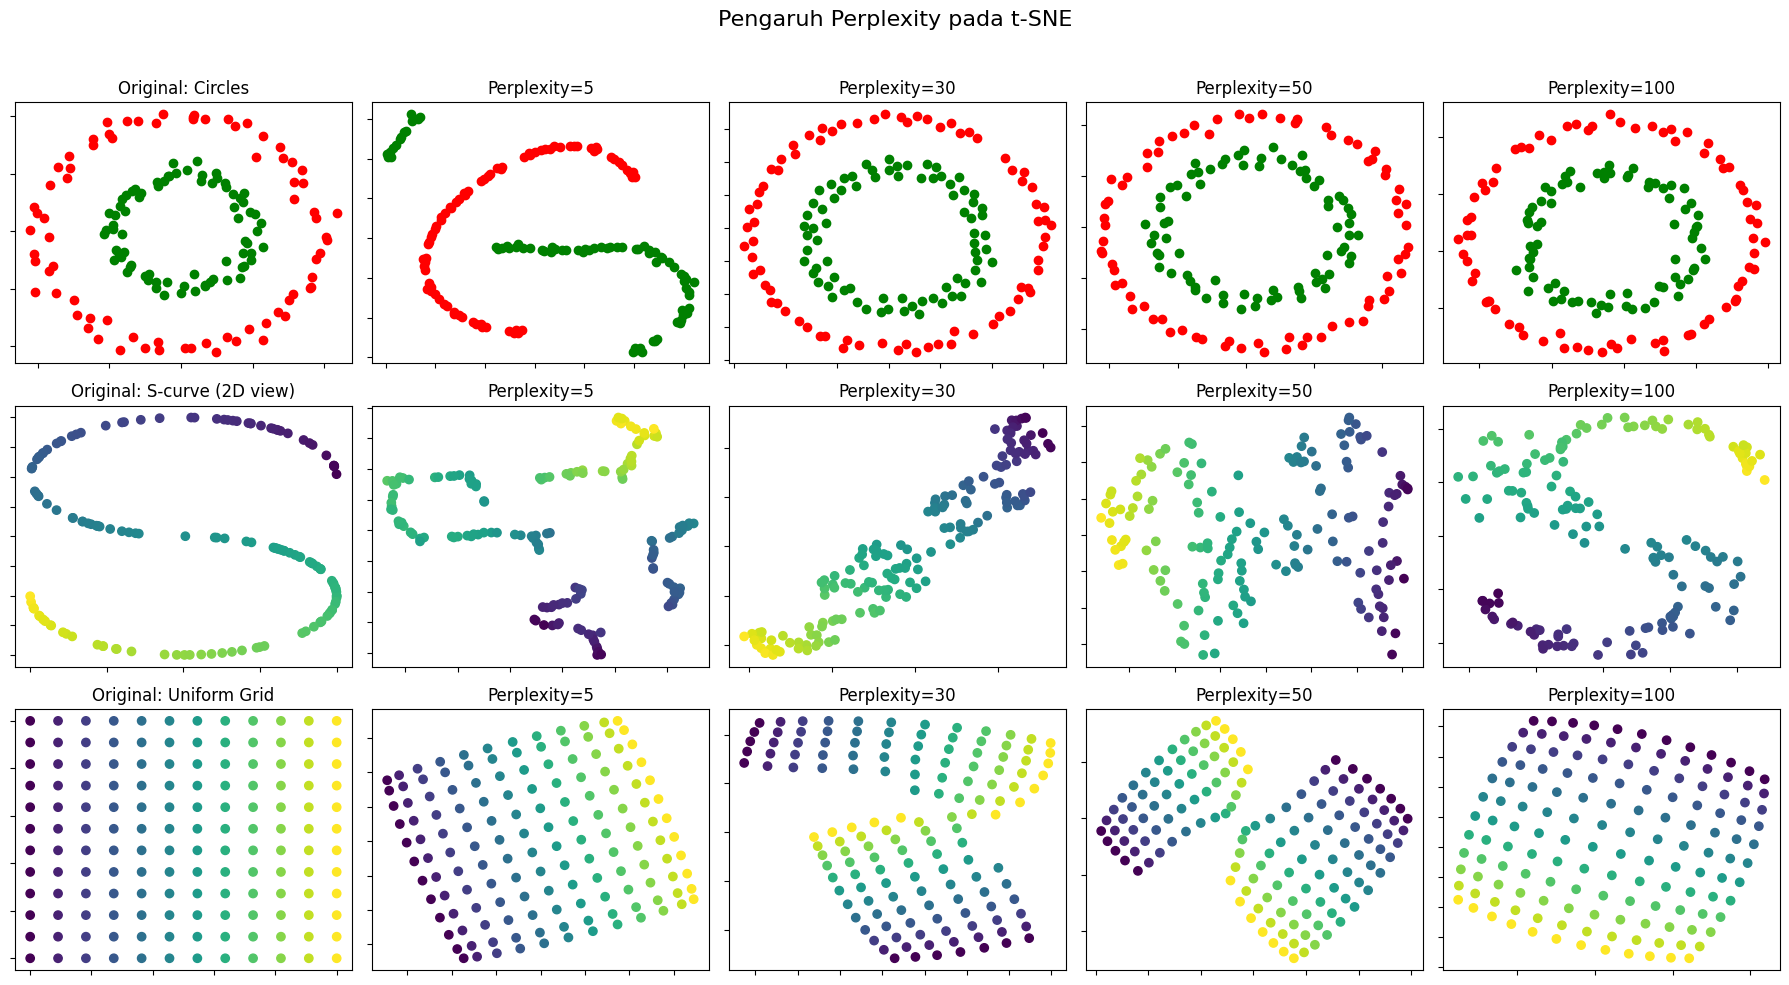

In [ ]:
fig, subplots = plt.subplots(3, 5, figsize=(18, 10))
fig.suptitle("Pengaruh Perplexity pada t-SNE", fontsize=16)

X, y = datasets.make_circles(
    n_samples=n_samples,
    factor=0.5,
    noise=0.05,
    random_state=0,
)

red = y == 0
green = y == 1

ax = subplots[0][0]
ax.scatter(X[red, 0], X[red, 1], c="red", label="Class 0")
ax.scatter(X[green, 0], X[green, 1], c="green", label="Class 1")
ax.set_title("Original: Circles")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
ax.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[0][i + 1]

    t0 = time()
    Y = run_tsne(X, perplexity=perplexity, max_iter=500)
    t1 = time()

    print(f"circles, perplexity={perplexity} in {t1 - t0:.2f} sec")

    ax.scatter(Y[red, 0], Y[red, 1], c="red")
    ax.scatter(Y[green, 0], Y[green, 1], c="green")
    ax.set_title(f"Perplexity={perplexity}")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")

X, color = datasets.make_s_curve(n_samples, random_state=0)

ax = subplots[1][0]
ax.scatter(X[:, 0], X[:, 2], c=color, cmap="viridis")
ax.set_title("Original: S-curve (2D view)")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
ax.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[1][i + 1]

    t0 = time()
    Y = run_tsne(X, perplexity=perplexity, max_iter=500)
    t1 = time()

    print(f"S-curve, perplexity={perplexity} in {t1 - t0:.2f} sec")

    ax.scatter(Y[:, 0], Y[:, 1], c=color, cmap="viridis")
    ax.set_title(f"Perplexity={perplexity}")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")

x = np.linspace(0, 1, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, x)

X = np.hstack(
    [
        xx.ravel().reshape(-1, 1),
        yy.ravel().reshape(-1, 1),
    ]
)

color = xx.ravel()

ax = subplots[2][0]
ax.scatter(X[:, 0], X[:, 1], c=color, cmap="viridis")
ax.set_title("Original: Uniform Grid")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
ax.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[2][i + 1]

    t0 = time()
    Y = run_tsne(X, perplexity=perplexity, max_iter=500)
    t1 = time()

    print(f"uniform grid, perplexity={perplexity} in {t1 - t0:.2f} sec")

    ax.scatter(Y[:, 0], Y[:, 1], c=color, cmap="viridis")
    ax.set_title(f"Perplexity={perplexity}")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Eksperimen Tambahan

Dataset *circles* dengan 300 sampel dan perplexity 5, 20, 30, 50.

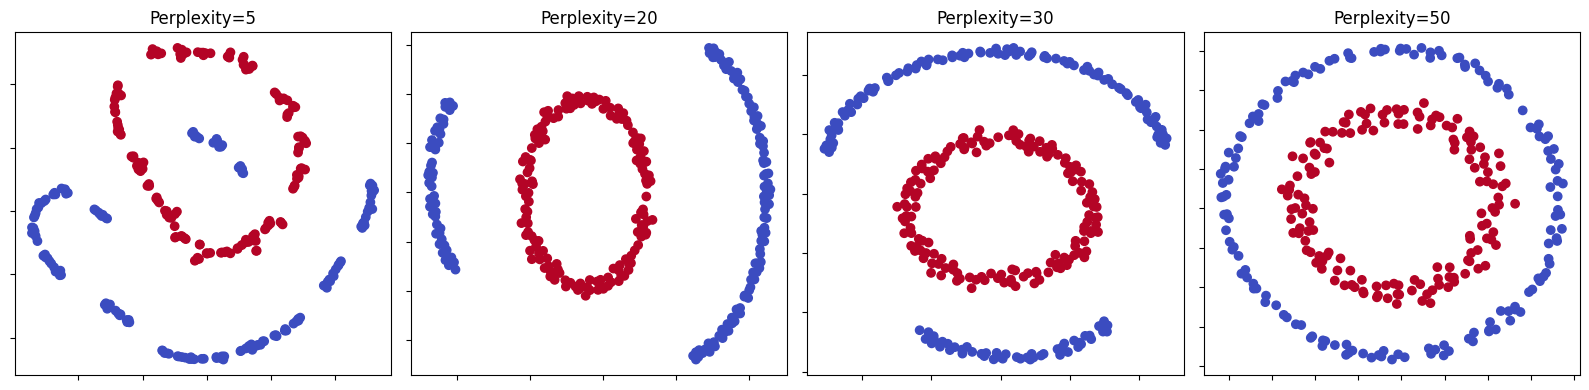

In [ ]:
X, y = datasets.make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42,
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, perplexity in zip(axes, [5, 20, 30, 50]):
    Y = run_tsne(X, perplexity=perplexity, max_iter=800)
    ax.scatter(Y[:, 0], Y[:, 1], c=y, cmap="coolwarm")
    ax.set_title(f"Perplexity={perplexity}")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")

plt.tight_layout()
plt.show()